In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_curve,
    roc_auc_score
    )

In [ ]:
data = load_breast_cancer()
X = data.data
y = data.target
print("Number of samples:", X.shape[0])
print("Number of features:", X.shape[1])

Number of samples: 569
Number of features: 30


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
X,
y,
test_size=0.2,
random_state=42
)

In [ ]:
dt_model = DecisionTreeClassifier(
random_state=42
)
nb_model = GaussianNB()

In [ ]:
dt_model.fit(X_train, y_train)
nb_model.fit(X_train, y_train)

GaussianNB()

In [ ]:
y_pred_dt = dt_model.predict(X_test)
y_pred_nb = nb_model.predict(X_test)

In [ ]:
cm_dt = confusion_matrix(y_test, y_pred_dt)
print("Decision Tree Confusion Matrix:")
print(cm_dt)

Decision Tree Confusion Matrix:
[[40  3]
 [ 3 68]]


In [ ]:
accuracy_dt = accuracy_score(y_test, y_pred_dt)
precision_dt = precision_score(
    y_test, y_pred_dt
    )

recall_dt = recall_score(
    y_test, y_pred_dt
    )

f1_dt = f1_score(
    y_test, y_pred_dt
    )

print("Decision Tree")
print("Accuracy :", accuracy_dt)
print("Precision:", precision_dt)
print("Recall :", recall_dt)
print("F1-score :", f1_dt)

Decision Tree
Accuracy : 0.9473684210526315
Precision: 0.9577464788732394
Recall : 0.9577464788732394
F1-score : 0.9577464788732394


In [ ]:
cm_nb = confusion_matrix(y_test, y_pred_nb)
print("Naive Bayes Confusion Matrix:")
print(cm_nb)

Naive Bayes Confusion Matrix:
[[40  3]
 [ 0 71]]


In [ ]:
accuracy_nb = accuracy_score(y_test, y_pred_nb)
precision_nb = precision_score(
y_test, y_pred_nb
)

recall_nb = recall_score(
y_test, y_pred_nb
)
f1_nb = f1_score(
y_test, y_pred_nb
)
print("Gaussian Naive Bayes")
print("Accuracy :", accuracy_nb)
print("Precision:", precision_nb)
print("Recall :", recall_nb)
print("F1-score :", f1_nb)

Gaussian Naive Bayes
Accuracy : 0.9736842105263158
Precision: 0.9594594594594594
Recall : 1.0
F1-score : 0.9793103448275862


In [ ]:
y_prob_dt = dt_model.predict_proba(X_test)[:, 1]
y_prob_nb = nb_model.predict_proba(X_test)[:, 1]

In [ ]:
fpr_dt, tpr_dt, thresholds_dt = roc_curve(
y_test, y_prob_dt
)


fpr_nb, tpr_nb, thresholds_nb = roc_curve(
y_test, y_prob_nb
)

In [ ]:
auc_dt = roc_auc_score(
y_test, y_prob_dt
)

auc_nb = roc_auc_score(
y_test, y_prob_nb
)

print("Decision Tree AUC:", auc_dt)
print("Naive Bayes AUC:", auc_nb)

Decision Tree AUC: 0.9439895185063871
Naive Bayes AUC: 0.9983622666229938


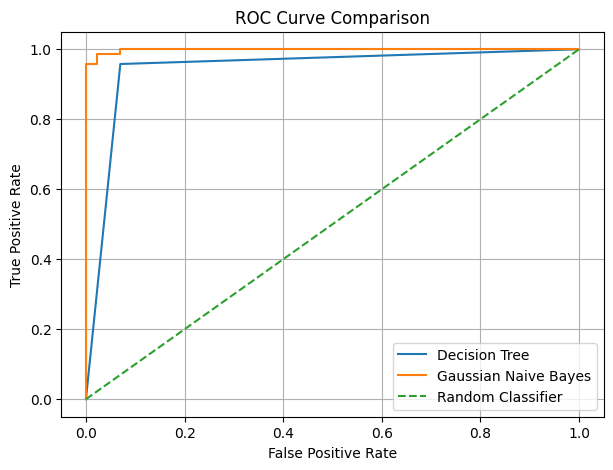

In [ ]:
plt.figure(figsize=(7, 5))
plt.plot(
    fpr_dt,
    tpr_dt,
    label="Decision Tree"
    )

plt.plot(
    fpr_nb,
    tpr_nb,
    label="Gaussian Naive Bayes"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
    )

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.grid()
plt.show()

In [ ]:
comparison = pd.DataFrame({
"Metric": [
"Accuracy",
"Precision",
"Recall",
"F1-score",
"AUC"
],
"Decision Tree": [
accuracy_dt,
precision_dt,
recall_dt,
f1_dt,
                   auc_dt
],
"Gaussian Naive Bayes": [
accuracy_nb,
precision_nb,
recall_nb,
f1_nb,
auc_nb
]
})
print(comparison)

      Metric  Decision Tree  Gaussian Naive Bayes
0   Accuracy       0.947368              0.973684
1  Precision       0.957746              0.959459
2     Recall       0.957746              1.000000
3   F1-score       0.957746              0.979310
4        AUC       0.943990              0.998362


In [ ]:
ewu